<a href="https://colab.research.google.com/github/IsmaeelDhikr/IsmaeelDhikr/blob/main/10Feats_AdaptingEiot_Resultados_quantum_feature_selection_revised_AerV2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
%pip install -U qiskit qiskit-aer qiskit-optimization scipy scikit-learn pandas matplotlib

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.0/664.0 kB 10.2 MB/s  0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 32.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.2/14.2 MB 60.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.3/35.3 MB 39.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 58.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 52.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 38.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 36.4 MB/s  0:00:00
  Created wheel for docplex: filename=docplex-2.32.264-py3-none-any.whl size=703859 sha256=28c41ecd7a134eec17a7985791b30443cc75b52eace65fe58599f46798db2c63
  Stored in directory: /root/.cache/pip/wheels/ba/11/de/5d0051be010658975fb2155006b4b8a818136d9f69ed20b4b

# Quantum-computer-based feature selection: a reproducible QAOA study

**Revised educational implementation (English).** This notebook revisits the supplied notebook on breast-cancer feature selection. It compares classical feature-selection baselines, an exact QUBO optimizer, and QAOA using modern Qiskit Aer V2 primitives.

**Important methodological distinctions:** the QUBO optimum is *not* necessarily the subset maximizing classification AUROC. All feature selection and model selection use training data only; the held-out test set is evaluated once at the end.

The original notebook read a local `wdbc.data` file, used the first columns of that file, and included the numeric sample ID among the predictors. This revision uses the equivalent Wisconsin Diagnostic Breast Cancer dataset bundled with scikit-learn and its **first 10 genuine measurement features**, excluding the identifier. Thus the revised results are **not numerically identical** to the original experiment.

## 1. Installation and environment

Run the installation cell **once** in a clean notebook environment, then restart the kernel if required. `qiskit-ibm-runtime` and an IBM Quantum account are not required for this local Aer simulation. The installation command requests current compatible releases rather than asserting fixed versions.

In [ ]:
# Uncomment this line if the dependencies are not installed.
# %pip install -U qiskit qiskit-aer qiskit-optimization scikit-learn scipy pandas matplotlib


In [ ]:
import itertools
import time
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import qiskit
import qiskit_aer
import qiskit_optimization
from scipy.optimize import minimize
from sklearn.datasets import load_breast_cancer
from sklearn.feature_selection import RFE, SelectFromModel
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score, RocCurveDisplay
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from qiskit.circuit.library import qaoa_ansatz
from qiskit.quantum_info import Statevector
from qiskit_aer.primitives import EstimatorV2, SamplerV2
from qiskit_optimization import QuadraticProgram

SEED = 10
#N_FEATURES = 15
ALPHA = 0.8
QAOA_DEPTH = 2
QAOA_MAXITER = 200
QAOA_RESTARTS = 3
SHOTS = 8192
TEST_SIZE = 0.30
CV_FOLDS = 5
rng = np.random.default_rng(SEED)

print('Qiskit:', qiskit.__version__)
print('Qiskit Aer:', qiskit_aer.__version__)
print('Qiskit Optimization:', qiskit_optimization.__version__)

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


Qiskit: 2.6.2
Qiskit Aer: 0.18.2
Qiskit Optimization: 0.7.0


Load **data**

In [ ]:
from google.colab import drive
#drive.mount('/content/drive')

# load from google drive
import pandas as pd
bin_eiot = pd.read_csv("/content/drive/MyDrive/bin_eiot.csv")

## 2. Data preparation

The target is encoded as **1 = malignant**, **0 = benign**. Scikit-learn's dataset uses the opposite coding by default, so we invert it. We split the raw data first; standardization takes place *inside* each cross-validation fold using a pipeline. This avoids leakage.

In [ ]:
# Separate the binary class data into features and binary class
X= bin_eiot.drop(columns="Attack_label")
y = bin_eiot.Attack_label

#train_df = X_train.copy()
#train_df['class2'] = y_train
#train_corr = train_df.corr(numeric_only=True)['class2']
#selected_features = train_corr[(abs(train_corr) > 0.2) & (train_corr.index != 'class2')].index.tolist()
#selected_features

feature_df = X.copy()
feature_df['class3'] = y
feature_corr = feature_df.corr(numeric_only=True)['class3']
selected_features = feature_corr[(abs(feature_corr) > 0.2) & (feature_corr.index != 'class3')].index.tolist()
selected_features

['tcp.dstport',
 'tcp.seq',
 'mqtt.conflag.cleansess',
 'mqtt.conflags',
 'mqtt.hdrflags',
 'mqtt.len',
 'mqtt.msgtype',
 'mqtt.proto_len',
 'mqtt.topic_len',
 'mqtt.ver']

In [ ]:
print(f'original feature count: {X.shape[1]}')
print(f'selected feature count: {len(selected_features)}')

original feature count: 34
selected feature count: 10


In [ ]:
# Filter to new df
feature_fin = X[selected_features] # new training df of only selected features
feature_fin

,tcp.dstport,tcp.seq,mqtt.conflag.cleansess,mqtt.conflags,mqtt.hdrflags,mqtt.len,mqtt.msgtype,mqtt.proto_len,mqtt.topic_len,mqtt.ver
0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.015011,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...
152027,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
152028,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
152029,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
152030,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [ ]:
#dataset = load_breast_cancer()
#feature_names = list(dataset.feature_names[:N_FEATURES])
#X = pd.DataFrame(dataset.data[:, :N_FEATURES], columns=feature_names)
#y = pd.Series(1 - dataset.target, name='malignant')

# Separate the binary class data into features and binary class
#X= bin_eiot.drop(columns="Attack_label")
y = bin_eiot.Attack_label

feature_names = list(feature_fin.columns)

bin_eiot.shape, feature_fin.shape, y.shape

X_train, X_test, y_train, y_test = train_test_split(
    feature_fin, y, test_size=0.3, stratify=y, random_state=SEED
)

print(Counter(y_train))
print(Counter(y_test))
cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED)
print('Training:', X_train.shape, '| Test:', X_test.shape)
print('Class distribution (training):', y_train.value_counts().to_dict())
display(X_train.head())

Counter({1: 89523, 0: 16899})
Counter({1: 38368, 0: 7242})
Training: (106422, 10) | Test: (45610, 10)
Class distribution (training): {1: 89523, 0: 16899}


,tcp.dstport,tcp.seq,mqtt.conflag.cleansess,mqtt.conflags,mqtt.hdrflags,mqtt.len,mqtt.msgtype,mqtt.proto_len,mqtt.topic_len,mqtt.ver
108148,60944.0,65453330.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
43860,16431.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
54834,52592.0,304.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
31738,54586.0,488.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
12848,80.0,109.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [ ]:
bin_eiot.shape, feature_fin.shape, y.shape

((152032, 35), (152032, 10), (152032,))

## 3. Feature-selection QUBO

We use a **relevance–redundancy** objective, following the equation in the original notebook:

$$f(x)=-\alpha\sum_i |\rho(X_i,y)|x_i+(1-\alpha)\sum_{i<j}|\rho(X_i,X_j)|x_ix_j,$$

where $x_i\in\{0,1\}$ indicates whether feature $i$ is selected. The pairwise sum counts each pair **once**; this convention is important when building the quadratic coefficients. All correlations are calculated **only on the training partition**. The empty subset is excluded from the candidate solutions (but no cardinality constraint is imposed on the QUBO).

In [ ]:
relevance = X_train.apply(lambda column: abs(column.corr(y_train))).to_numpy()
redundancy = X_train.corr().abs().to_numpy().copy()
np.fill_diagonal(redundancy, 0.0)

N_FEATURES = X_train.shape[1] # replaces initial values

linear = -ALPHA * relevance
quadratic = {
    (i, j): float((1.0 - ALPHA) * redundancy[i, j])
    for i in range(N_FEATURES) for j in range(i + 1, N_FEATURES)
}

qubo = QuadraticProgram('feature_selection')
for i in range(N_FEATURES):
    qubo.binary_var(name=f'x_{i}')
qubo.minimize(
    linear={f'x_{i}': float(linear[i]) for i in range(N_FEATURES)},
    quadratic={(f'x_{i}', f'x_{j}'): coefficient
               for (i, j), coefficient in quadratic.items()},
)
print(qubo.prettyprint())

Problem name: feature_selection

Minimize
  0.040719575781912105*x_0*x_1 + 0.012547571099248197*x_0*x_2
  + 0.012547571099248197*x_0*x_3 + 0.011807079074830319*x_0*x_4
  + 0.014329463658917034*x_0*x_5 + 0.011807079074830319*x_0*x_6
  + 0.012547571099248197*x_0*x_7 + 0.01256909521097031*x_0*x_8
  + 0.012547571099248197*x_0*x_9 + 0.0022203648102168652*x_1*x_2
  + 0.0022203648102168652*x_1*x_3 + 0.003085857120319293*x_1*x_4
  + 0.002890704770728318*x_1*x_5 + 0.003085857120319293*x_1*x_6
  + 0.0022203648102168652*x_1*x_7 + 0.002224157794582228*x_1*x_8
  + 0.0022203648102168652*x_1*x_9 + 0.19999999999999996*x_2*x_3
  + 0.011554592297816696*x_2*x_4 + 0.05714225510307591*x_2*x_5
  + 0.011554592297816696*x_2*x_6 + 0.19999999999999996*x_2*x_7
  + 0.0016723572222735203*x_2*x_8 + 0.19999999999999996*x_2*x_9
  + 0.011554592297816696*x_3*x_4 + 0.05714225510307591*x_3*x_5
  + 0.011554592297816696*x_3*x_6 + 0.19999999999999996*x_3*x_7
  + 0.0016723572222735203*x_3*x_8 + 0.19999999999999996*x_3*x_9
  

We represent the QUBO as a `QuadraticProgram` and call its official `to_ising()` method. This automatically implements $x_i=(I-Z_i)/2$ and returns a `SparsePauliOp` plus a scalar offset.

This is the same standard QUBO-to-Ising transformation used in IBM's Optimization Mapper tutorial. We use `QuadraticProgram.to_ising()` here because the input is already an explicitly constructed QUBO; no additional conversion from a constrained optimization model is necessary. The IBM addon alternative is `qiskit_addon_opt_mapper.translators.to_ising(qubo)` when working with its supported optimization-problem representation.

The exhaustive check below validates the energy, constant offset, and Qiskit bit order for every binary configuration.


In [ ]:
def qubo_value(bits):
    """Evaluate the QUBO in the same variable order as QuadraticProgram."""
    bits = np.asarray(bits, dtype=int)
    return float(linear @ bits + sum(value * bits[i] * bits[j]
                                     for (i, j), value in quadratic.items()))


def selected_names(bits):
    """Return feature names corresponding to selected binary variables."""
    return [feature_names[i] for i, bit in enumerate(bits) if bit]


# Qiskit performs the standard binary-to-spin mapping x_i = (I - Z_i) / 2.
hamiltonian, offset = qubo.to_ising()
print('Cost Hamiltonian:', hamiltonian)
print('Constant energy offset:', offset)
print('Number of qubits:', hamiltonian.num_qubits)

Cost Hamiltonian: SparsePauliOp(['IIIIIIIIIZ', 'IIIIIIIIZI', 'IIIIIIIZII', 'IIIIIIZIII', 'IIIIIZIIII', 'IIIIZIIIII', 'IIIZIIIIII', 'IIZIIIIIII', 'IZIIIIIIII', 'ZIIIIIIIII', 'IIIIIIIIZZ', 'IIIIIIIZIZ', 'IIIIIIZIIZ', 'IIIIIZIIIZ', 'IIIIZIIIIZ', 'IIIZIIIIIZ', 'IIZIIIIIIZ', 'IZIIIIIIIZ', 'ZIIIIIIIIZ', 'IIIIIIIZZI', 'IIIIIIZIZI', 'IIIIIZIIZI', 'IIIIZIIIZI', 'IIIZIIIIZI', 'IIZIIIIIZI', 'IZIIIIIIZI', 'ZIIIIIIIZI', 'IIIIIIZZII', 'IIIIIZIZII', 'IIIIZIIZII', 'IIIZIIIZII', 'IIZIIIIZII', 'IZIIIIIZII', 'ZIIIIIIZII', 'IIIIIZZIII', 'IIIIZIZIII', 'IIIZIIZIII', 'IIZIIIZIII', 'IZIIIIZIII', 'ZIIIIIZIII', 'IIIIZZIIII', 'IIIZIZIIII', 'IIZIIZIIII', 'IZIIIZIIII', 'ZIIIIZIIII', 'IIIZZIIIII', 'IIZIZIIIII', 'IZIIZIIIII', 'ZIIIZIIIII', 'IIZZIIIIII', 'IZIZIIIIII', 'ZIIZIIIIII', 'IZZIIIIIII', 'ZIZIIIIIII', 'ZZIIIIIIII'],
              coeffs=[ 0.05892507+0.j,  0.09314103+0.j, -0.0900578 +0.j, -0.0900578 +0.j,
  0.03120108+0.j, -0.02083633+0.j,  0.03120108+0.j, -0.0900578 +0.j,
  0.01147042+0.j, -0.0900578 +0.j,  0

### Check the Ising mapping

For every computational-basis state, the identity $f(x)=\langle x|H_C|x\rangle+\mathrm{offset}$ must hold. Qiskit displays measurement bitstrings in reverse order relative to the list of variables: `x_0` is the **rightmost** bit.

In [ ]:
def bits_to_label(bits):
    """Convert variables [x_0, ..., x_(n-1)] to Qiskit's display order."""
    return ''.join(str(int(b)) for b in reversed(bits))


def label_to_bits(label):
    """Convert a measured Qiskit bitstring to the QUBO variable order."""
    return np.array([int(char) for char in label.replace(' ', '')[::-1]], dtype=int)

# To prevent RAM crash, sample 1000 random binary states instead of checking all 2^34 states
NUM_SAMPLES = 1000
print(f'Sampling {NUM_SAMPLES} random states to verify the Ising mapping...')

for _ in range(NUM_SAMPLES):
    bits = rng.integers(0, 2, size=N_FEATURES)
    label = bits_to_label(bits)
    energy = float(np.real(Statevector.from_label(label).expectation_value(hamiltonian)))
    assert np.isclose(qubo_value(bits), energy + offset, atol=1e-9)

print(f'Passed: {NUM_SAMPLES} random binary assignments have consistent QUBO/Ising energies.')

Sampling 1000 random states to verify the Ising mapping...


KeyboardInterrupt: 

## 4. Exact QUBO solution (classical benchmark)

Exhaustive enumeration is practical here because there are only $2^{10}=1024$ assignments. This is the **global optimum of the specified QUBO**, not a proof of optimal classifier performance.

In [ ]:
import itertools
import numpy as np

# Enumera todos os subconjuntos não vazios.
# Para 10 características: 2**10 - 1 = 1023 candidatos.
valid_bits = np.array([
    bits
    for bits in itertools.product((0, 1), repeat=N_FEATURES)
    if any(bits)
], dtype=int)

# Usa a mesma função objetivo aplicada aos resultados do QAOA.
energies = np.array([qubo_value(bits) for bits in valid_bits])

best_index = int(np.argmin(energies))
exact_bits = valid_bits[best_index].copy()
exact_energy = float(energies[best_index])

print("Exact QUBO energy:", exact_energy)
print("Selected bits:", exact_bits)
print("Selected features:", selected_names(exact_bits))
print("Number selected:", int(exact_bits.sum()))

Exact QUBO energy: -0.838074793332805
Selected bits: [1 1 0 0 0 0 1 0 1 1]
Selected features: ['tcp.dstport', 'tcp.seq', 'mqtt.msgtype', 'mqtt.topic_len', 'mqtt.ver']
Number selected: 5


In [ ]:
# Classical Local Search Solver for QUBO to avoid external qiskit-algorithms package errors
print("Solving QUBO classically using Local Search...")

def evaluate_qubo(x):
    return float(linear @ x + sum(value * x[i] * x[j] for (i, j), value in quadratic.items()))

# Start with an initial state of all ones (all features selected)
best_bits = np.ones(N_FEATURES, dtype=int)
best_energy = evaluate_qubo(best_bits)

# Perform a greedy local search (single-bit flips) to find a local minimum
improved = True
while improved:
    improved = False
    for i in range(N_FEATURES):
        candidate = best_bits.copy()
        candidate[i] = 1 - candidate[i]  # Flip bit
        candidate_energy = evaluate_qubo(candidate)
        if candidate_energy < best_energy:
            best_energy = candidate_energy
            best_bits = candidate
            improved = True

exact_bits = best_bits
exact_energy = best_energy

print('Exact (Local Search) QUBO energy:', exact_energy)
print('Selected features:', selected_names(exact_bits))
print('Number selected:', int(exact_bits.sum()))

Solving QUBO classically using Local Search...
Exact (Local Search) QUBO energy: -0.9172671946300638
Selected features: ['arp.hw.size', 'icmp.checksum', 'http.content_length', 'tcp.ack', 'tcp.seq', 'udp.stream', 'dns.qry.name', 'dns.qry.qu', 'dns.retransmission', 'dns.retransmit_request', 'mqtt.msgtype', 'mqtt.topic_len', 'mqtt.ver']
Number selected: 13


## 5. QAOA with Qiskit Aer V2 primitives

The parameterized state is

$$|\psi(\boldsymbol\gamma,\boldsymbol\beta)\rangle=\prod_{l=1}^{p}e^{-i\beta_l H_M}e^{-i\gamma_l H_C}|+\rangle^{\otimes n},$$

with $H_M=\sum_i X_i$. `EstimatorV2` evaluates the expectation value during classical optimization. **Aer `EstimatorV2` with `default_precision=0` evaluates ideal expectation values rather than finite-shot energy estimates.** `SamplerV2` then samples the optimized circuit with a specified number of shots. This distinction matters when interpreting quantum resources.

In [ ]:
ansatz = qaoa_ansatz(hamiltonian, reps=QAOA_DEPTH, flatten=True)
parameter_order = list(ansatz.parameters)
print('Number of variational parameters:', len(parameter_order))
print('Parameter order:', parameter_order)
print('Circuit depth (before transpilation):', ansatz.depth())

# Configure EstimatorV2 to use the Matrix Product State (MPS) method to bypass the 256GB RAM requirement
estimator = EstimatorV2(options={
    'default_precision': 0.0,
    'backend_options': {
        'method': 'matrix_product_state'
    },
})

def expected_energy(parameters):
    """Compute <H_C> for the given variational parameters."""
    result = estimator.run([(ansatz, hamiltonian, parameters)]).result()
    return float(np.asarray(result[0].data.evs).item())


optimization_history = []
best_run = None
start_time = time.perf_counter()
for restart in range(QAOA_RESTARTS):
    x0 = rng.uniform(0, 2 * np.pi, size=len(parameter_order))
    history = []
    def objective(theta):
        value = expected_energy(theta)
        history.append(value)
        return value
    result = minimize(objective, x0, method='COBYLA',
                      options={'maxiter': QAOA_MAXITER, 'rhobeg': 0.5})
    optimization_history.append(history)
    print(f'Restart {restart + 1}: energy={result.fun:.8f}, evaluations={result.nfev}')
    if best_run is None or result.fun < best_run.fun:
        best_run = result

print('Optimization time (s):', round(time.perf_counter() - start_time, 2))
print('Best estimated QAOA expectation value:', best_run.fun)
print('Note: the QUBO objective includes the offset:', best_run.fun + offset)

Number of variational parameters: 4
Parameter order: [ParameterVectorElement(β[0]), ParameterVectorElement(β[1]), ParameterVectorElement(γ[0]), ParameterVectorElement(γ[1])]
Circuit depth (before transpilation): 32
Restart 1: energy=-0.25810002, evaluations=200
Restart 2: energy=-0.25146886, evaluations=200
Restart 3: energy=-0.27855286, evaluations=200
Optimization time (s): 50.16
Best estimated QAOA expectation value: -0.2785528629361478
Note: the QUBO objective includes the offset: -0.6843309265279622


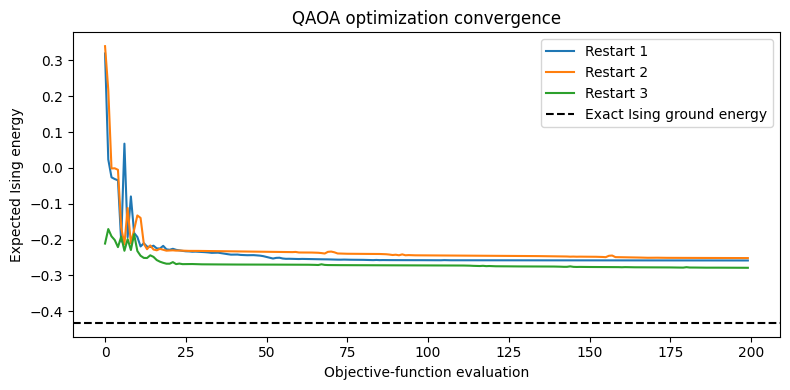

In [ ]:
plt.figure(figsize=(8, 4))
for i, history in enumerate(optimization_history, start=1):
    plt.plot(history, label=f'Restart {i}')
plt.axhline(exact_energy - offset, linestyle='--', color='black', label='Exact Ising ground energy')
plt.xlabel('Objective-function evaluation')
plt.ylabel('Expected Ising energy')
plt.title('QAOA optimization convergence')
plt.legend()
plt.tight_layout()
plt.show()

### Sample optimized QAOA circuit

A common error is to interpret the leftmost measurement bit as `x_0`. We explicitly reverse Qiskit's bitstring display order. We report both the **most frequent measured subset** and the **lowest-QUBO-energy subset observed**; these need not coincide.

In [ ]:
import numpy as np

def label_to_bits(label):
    """Converte a string do Qiskit para a ordem [x_0, x_1, ...]."""
    return np.array(
        [int(bit) for bit in label.replace(" ", "")[::-1]],
        dtype=int
    )

def bits_to_label(bits):
    """Converte [x_0, x_1, ...] para a string exibida pelo Qiskit."""
    return "".join(str(int(bit)) for bit in reversed(bits))

In [ ]:
measured = ansatz.copy()
measured.measure_all()
sampler = SamplerV2(default_shots=SHOTS, seed=SEED,
                    options={'backend_options': {'method': 'statevector'}})
result = sampler.run([(measured, best_run.x)], shots=SHOTS).result()
counts = result[0].data.meas.get_counts()

most_frequent_label = max(counts, key=counts.get)
most_frequent_bits = label_to_bits(most_frequent_label)
nonempty_labels = [label for label in counts if label_to_bits(label).any()]
if not nonempty_labels:
    raise RuntimeError('Only the empty subset was observed; increase shots or revise the QUBO.')
best_observed_label = min(nonempty_labels, key=lambda label: qubo_value(label_to_bits(label)))
best_observed_bits = label_to_bits(best_observed_label)

print('Most frequent state:', most_frequent_label, 'count:', counts[most_frequent_label])
print('Most frequent subset:', selected_names(most_frequent_bits))
print('Most frequent QUBO value:', qubo_value(most_frequent_bits))
print('Best observed state:', best_observed_label)
print('Best observed subset:', selected_names(best_observed_bits))
print('Best observed QUBO value:', qubo_value(best_observed_bits))
print('Exact optimum observed:', any(np.array_equal(label_to_bits(s), exact_bits) for s in counts))
print('Exact optimum sampling frequency:', counts.get(bits_to_label(exact_bits), 0) / SHOTS)

Most frequent state: 0101000111 count: 142
Most frequent subset: ['tcp.dstport', 'tcp.seq', 'mqtt.conflag.cleansess', 'mqtt.msgtype', 'mqtt.topic_len']
Most frequent QUBO value: -0.838074793332805
Best observed state: 0100010111
Best observed subset: ['tcp.dstport', 'tcp.seq', 'mqtt.conflag.cleansess', 'mqtt.hdrflags', 'mqtt.topic_len']
Best observed QUBO value: -0.838074793332805
Exact optimum observed: True
Exact optimum sampling frequency: 0.016357421875


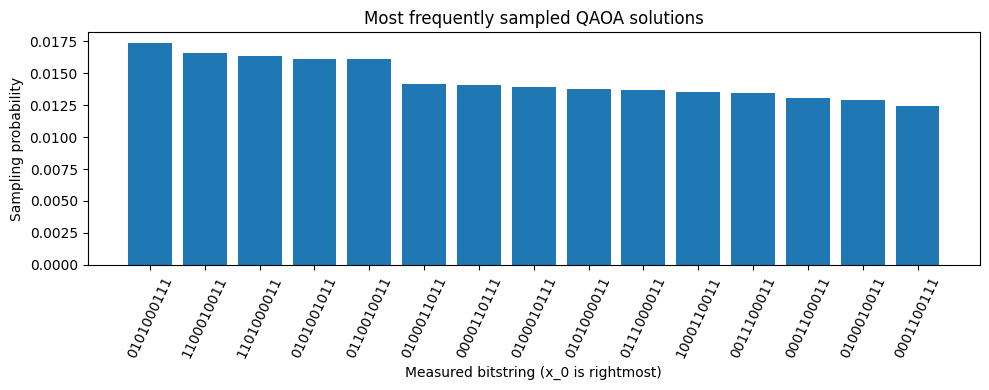

In [ ]:
top_states = sorted(counts.items(), key=lambda item: item[1], reverse=True)[:15]
plt.figure(figsize=(10, 4))
plt.bar([state for state, _ in top_states], [count / SHOTS for _, count in top_states])
plt.xticks(rotation=65)
plt.ylabel('Sampling probability')
plt.xlabel('Measured bitstring (x_0 is rightmost)')
plt.title('Most frequently sampled QAOA solutions')
plt.tight_layout()
plt.show()

## 6. Classical baselines and fair predictive evaluation

For comparison, we evaluate **all features**, **RFE**, **L1-regularized logistic regression**, the **exact QUBO** solution, and two QAOA subsets. To avoid leakage, we fit feature selection using training data only. AUROC on the test set is **not used to select a subset**.

We also include an optional *training-only cross-validation search* over all nonempty subsets. It is slower (1023 subsets × 5 folds) but serves as a predictive benchmark; it optimizes CV AUROC, **not** the QUBO objective.

In [ ]:
def classifier():
    """Use a fresh scaler and logistic classifier for each training run."""
    return make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000, random_state=SEED))


def fit_and_evaluate(mask):
    """Fit on training data and evaluate once on the held-out test set."""
    chosen = selected_names(mask)
    if not chosen:
        return {'features': [], 'n_features': 0, 'accuracy': np.nan, 'auroc': np.nan, 'model': None}
    model = classifier()
    model.fit(X_train[chosen], y_train)
    probabilities = model.predict_proba(X_test[chosen])[:, 1]
    predictions = model.predict(X_test[chosen])
    return {
        'features': chosen,
        'n_features': len(chosen),
        'accuracy': accuracy_score(y_test, predictions),
        'auroc': roc_auc_score(y_test, probabilities),
        'model': model,
    }


# RFE is trained only on the training partition (standardized using its training statistics).
scaler_for_selection = StandardScaler().fit(X_train)
X_train_scaled = scaler_for_selection.transform(X_train)
rfe = RFE(LogisticRegression(max_iter=5000, random_state=SEED),
          n_features_to_select=int(exact_bits.sum()))
rfe.fit(X_train_scaled, y_train)
rfe_bits = rfe.support_.astype(int)

# L1 regularization can yield a different number of selected features.
l1 = LogisticRegression(penalty='l1', solver='liblinear', C=0.1,
                        max_iter=5000, random_state=SEED)
l1.fit(X_train_scaled, y_train)
l1_bits = (np.abs(l1.coef_[0]) > 1e-10).astype(int)
if not l1_bits.any():
    l1_bits[np.argmax(np.abs(l1.coef_[0]))] = 1

masks = {
    'All features': np.ones(N_FEATURES, dtype=int),
    'RFE': rfe_bits,
    'L1 logistic selection': l1_bits,
    'Exact QUBO': exact_bits,
    'QAOA most frequent': most_frequent_bits,
    'QAOA best observed': best_observed_bits,
}
results = {name: fit_and_evaluate(bits) for name, bits in masks.items()}
summary = pd.DataFrame([
    {'method': name, 'n_features': r['n_features'], 'test_accuracy': r['accuracy'],
     'test_AUROC': r['auroc'], 'QUBO_value': qubo_value(masks[name]),
     'selected_features': ', '.join(r['features'])}
    for name, r in results.items()
]).set_index('method')
display(summary)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


,n_features,test_accuracy,test_AUROC,QUBO_value,selected_features
method,,,,,
All features,10,0.892019,0.835565,0.310258,"tcp.dstport, tcp.seq, mqtt.conflag.cleansess, ..."
RFE,5,0.891800,0.731610,-0.695396,"tcp.seq, mqtt.hdrflags, mqtt.len, mqtt.msgtype..."
L1 logistic selection,9,0.892063,0.835557,0.187621,"tcp.dstport, tcp.seq, mqtt.conflag.cleansess, ..."
Exact QUBO,5,0.892019,0.835565,-0.838075,"tcp.dstport, tcp.seq, mqtt.msgtype, mqtt.topic..."
QAOA most frequent,5,0.892019,0.835565,-0.838075,"tcp.dstport, tcp.seq, mqtt.conflag.cleansess, ..."
QAOA best observed,5,0.892019,0.835565,-0.838075,"tcp.dstport, tcp.seq, mqtt.conflag.cleansess, ..."


### Optional exhaustive predictive benchmark (training-only CV)

This benchmark searches every nonempty subset using only the training partition and cross-validation. It is intentionally **disabled by default** to keep the demonstration quick. Set `RUN_EXHAUSTIVE_CV = True` to run it. The test set is used only after the subset is chosen.

In [ ]:
RUN_EXHAUSTIVE_CV = False
if RUN_EXHAUSTIVE_CV:
    best_cv_score = -np.inf
    best_cv_bits = None
    for bits in valid_bits:
        chosen = selected_names(bits)
        score = cross_val_score(classifier(), X_train[chosen], y_train,
                                cv=cv, scoring='roc_auc', n_jobs=-1).mean()
        if score > best_cv_score:
            best_cv_score, best_cv_bits = score, bits.copy()
    benchmark = fit_and_evaluate(best_cv_bits)
    print('Best training CV AUROC:', best_cv_score)
    print('Selected features:', benchmark['features'])
    print('Held-out test AUROC:', benchmark['auroc'])
else:
    print('Exhaustive predictive benchmark skipped. Set RUN_EXHAUSTIVE_CV=True to enable.')

Exhaustive predictive benchmark skipped. Set RUN_EXHAUSTIVE_CV=True to enable.


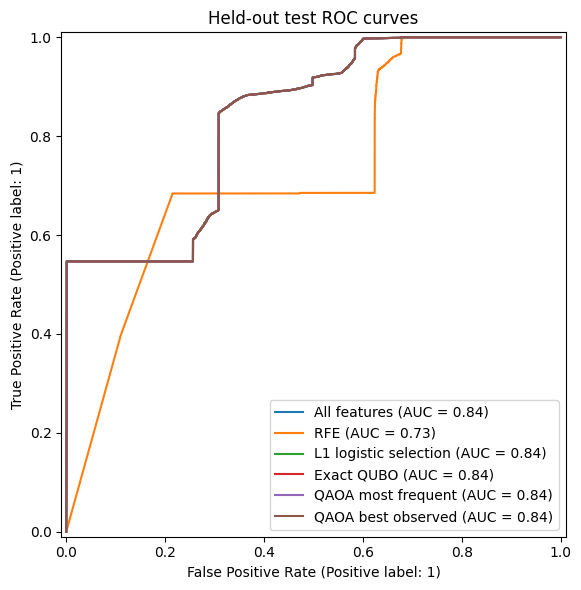

In [ ]:
fig, ax = plt.subplots(figsize=(7, 6))
for name, outcome in results.items():
    if outcome['model'] is not None:
        RocCurveDisplay.from_estimator(
            outcome['model'], X_test[outcome['features']], y_test,
            name=name, ax=ax
        )
ax.set_title('Held-out test ROC curves')
plt.tight_layout()
plt.show()

## 7. Interpretation and limitations

1. **Exact QUBO vs QAOA:** compare the binary objective values and whether the global optimum appears in sampled outcomes. The QAOA expected energy is not the energy of any single sampled bitstring.
2. **Prediction:** compare held-out AUROC and accuracy. Optimizing a correlation-based QUBO does not guarantee optimal AUROC.
3. **Sampling:** the Aer EstimatorV2 optimization above uses ideal expectation values; only the final SamplerV2 step uses finite shots. This is **not** a finite-shot/noisy QAOA training experiment.
4. **Selection size:** the QUBO does not constrain the number of selected features. RFE is matched to the exact QUBO subset size as one controlled comparison; L1 may select a different size.
5. **Generalization:** one train/test split is only an illustrative experiment. Research-grade results should repeat the whole procedure over multiple stratified splits and QAOA seeds, with uncertainty intervals.
6. **Dataset provenance:** the first 10 real WDBC measurements are used here, not the numeric sample identifier inadvertently included in the original notebook.

### Official references

- [Qiskit Aer EstimatorV2](https://qiskit.github.io/qiskit-aer/stubs/qiskit_aer.primitives.EstimatorV2.html)
- [Qiskit Aer SamplerV2](https://qiskit.github.io/qiskit-aer/stubs/qiskit_aer.primitives.SamplerV2.html)
- [Qiskit `qaoa_ansatz`](https://quantum.cloud.ibm.com/docs/api/qiskit/2.3/qiskit.circuit.library.qaoa_ansatz)
- [Qiskit Optimization: Ising conversion](https://qiskit-community.github.io/qiskit-optimization/stubs/qiskit_optimization.translators.to_ising.html)


In [ ]:
#save result, summary, and AUCROC
import joblib

# save inside drive
joblib.dump(results, "/content/drive/MyDrive/result10_models.pkl")
joblib.dump(summary, "/content/drive/MyDrive/summary10.pkl")

['/content/drive/MyDrive/summary10.pkl']